In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path("/content/drive/MyDrive/PlantDiseaseProject/PlantVillage")
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("Exists:", DATA_DIR.exists())
subdirs = sorted([p.name for p in DATA_DIR.iterdir() if p.is_dir()]) if DATA_DIR.exists() else []
print("Subdirectories count:", len(subdirs))
print("First 10 subdirs:", subdirs[:10])

Exists: True
Subdirectories count: 1
First 10 subdirs: ['Plant_leave_diseases_dataset_without_augmentation']


In [4]:
records = []
corrupted_files = []

for path in sorted(DATA_DIR.rglob("*")):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTS:
        class_name = path.parent.name
        try:
            with Image.open(path) as img:
                img.verify()
            with Image.open(path) as img_rgb:
                w, h = img_rgb.size
                mode = img_rgb.mode
            records.append({
                "path": str(path),
                "class_name": class_name,
                "width": w,
                "height": h,
                "mode": mode,
                "file_size_kb": round(path.stat().st_size / 1024, 2),
            })
        except Exception as exc:
            corrupted_files.append((str(path), str(exc)))

df = pd.DataFrame(records)
print(f"Total valid images: {len(df)}")
print(f"Corrupted images: {len(corrupted_files)}")
print(f"Unique classes: {df['class_name'].nunique() if not df.empty else 0}")
print("\nTop 5 classes:\n", df["class_name"].value_counts().head(5))
print("\nBottom 5 classes:\n", df["class_name"].value_counts().tail(5))

KeyboardInterrupt: 

Total images: 55448
Total classes: 39
Max / Min ratio: 36.23

Top 5:
 class_name
Orange___Haunglongbing_(Citrus_greening)    5507
Tomato___Tomato_Yellow_Leaf_Curl_Virus      5357
Soybean___healthy                           5090
Peach___Bacterial_spot                      2297
Tomato___Bacterial_spot                     2127
Name: count, dtype: int64

Bottom 5:
 class_name
Tomato___Tomato_mosaic_virus    373
Raspberry___healthy             371
Peach___healthy                 360
Apple___Cedar_apple_rust        275
Potato___healthy                152
Name: count, dtype: int64


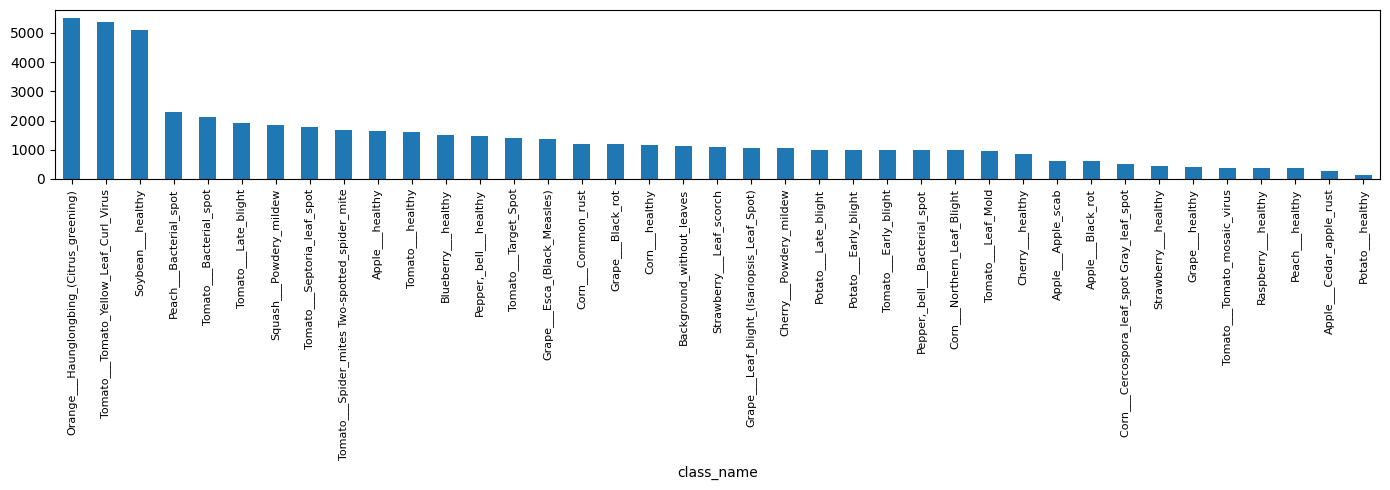

In [5]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path("/content/drive/MyDrive/PlantDiseaseProject/PlantVillage/Plant_leave_diseases_dataset_without_augmentation")
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

records = []
for root, _, files in os.walk(DATA_DIR):
    for name in files:
        if Path(name).suffix.lower() in IMAGE_EXTS:
            p = Path(root) / name
            records.append({
                "path": str(p),
                "class_name": p.parent.name,
                "size_kb": round(p.stat().st_size / 1024, 2),
            })

df = pd.DataFrame(records)
print("Total images:", len(df))
print("Total classes:", df["class_name"].nunique())
counts = df["class_name"].value_counts()
print("Max / Min ratio:", round(counts.iloc[0] / counts.iloc[-1], 2))
print("\nTop 5:\n", counts.head(5))
print("\nBottom 5:\n", counts.tail(5))

plt.figure(figsize=(14, 5))
counts.plot(kind="bar")
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.show()

Max / Min class count ratio: 36.23x
Potential duplicate candidates (same class & size_kb): 43324
Sample color modes: {'RGB': 200}
Top sample sizes (w, h): {(256, 256): 198, (256, 192): 2}


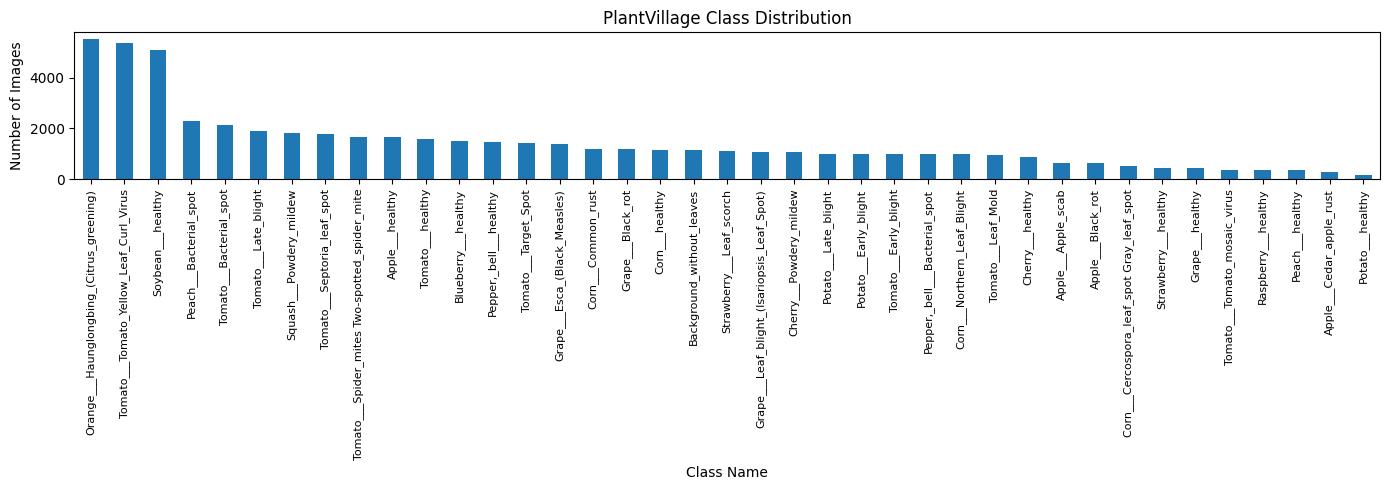

In [7]:
from PIL import Image

class_counts = df["class_name"].value_counts()
imbalance_ratio = class_counts.iloc[0] / class_counts.iloc[-1]
print(f"Max / Min class count ratio: {imbalance_ratio:.2f}x")

dup_candidates = int(df.duplicated(subset=["class_name", "size_kb"], keep=False).sum())
print(f"Potential duplicate candidates (same class & size_kb): {dup_candidates}")

sample_df = df.sample(n=min(200, len(df)), random_state=42)
modes, sizes = [], []
for p in sample_df["path"]:
    try:
        with Image.open(p) as img:
            modes.append(img.mode)
            sizes.append(img.size)
    except Exception:
        pass

print("Sample color modes:", pd.Series(modes).value_counts().to_dict())
print("Top sample sizes (w, h):", pd.Series(sizes).value_counts().head(5).to_dict())

plt.figure(figsize=(14, 5))
class_counts.plot(kind="bar")
plt.title("PlantVillage Class Distribution")
plt.xlabel("Class Name")
plt.ylabel("Number of Images")
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.show()

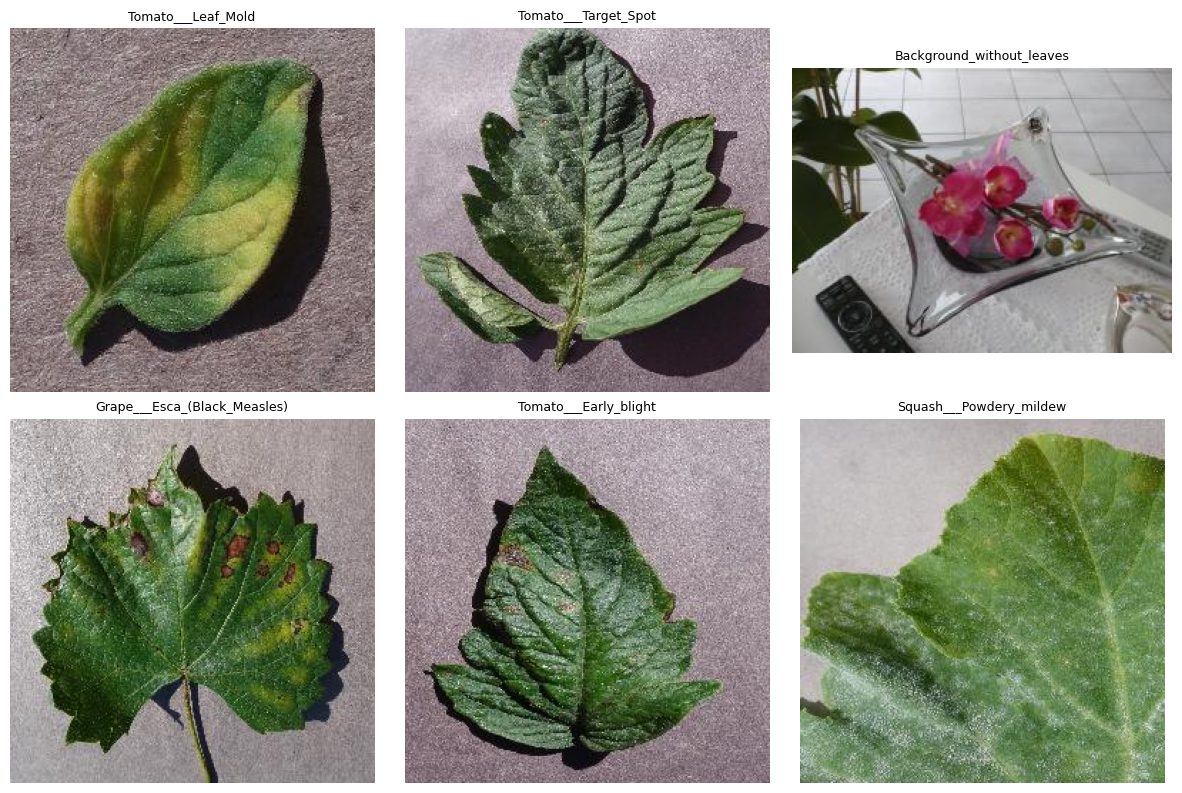

In [8]:
sample_classes = df["class_name"].drop_duplicates().sample(n=min(6, df["class_name"].nunique()), random_state=42)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for ax, cls in zip(axes, sample_classes):
    sample_row = df[df["class_name"] == cls].iloc[0]
    with Image.open(sample_row["path"]) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(cls[:28], fontsize=9)
    ax.axis("off")

for ax in axes[len(sample_classes):]:
    ax.axis("off")

plt.tight_layout()
plt.show()